In [186]:
from z2hex.geometry import HeavyHexLattice
from z2hex.circs import trotter_error

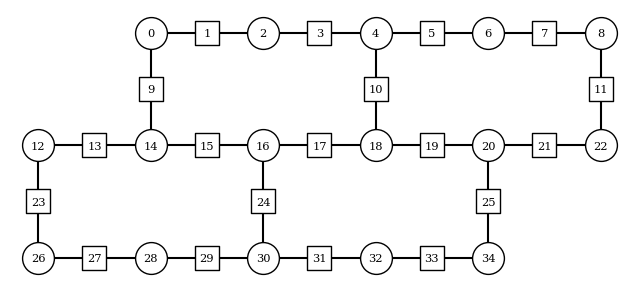

In [187]:
plaquette_width = 2
plaquette_height = 2

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
lattice.plot_lattice(number_qubits=True)

In [188]:
from sympy import symbols

m, g, lamb, t = symbols("m,g,λ,t")

trotter_error(t, lattice, m, g, lamb)

t**3*(76*Abs(g*λ**2) + 376*Abs(m*λ**2))/12 + t**3*(152*Abs(m**2*λ) + 304*Abs(g*m*λ) + 19*Abs(4*g**2*λ + 8*m**2*λ))/24

In [189]:
len(lattice.node_coords)

16

In [190]:
len(lattice.edge_coords)

19

In [191]:
76/19

4.0

In [192]:
304/19

16.0

In [193]:
152/19

8.0

In [194]:
3*6+2*10

38

In [195]:
47-38

9

In [196]:
376/(3*6 + 2*10)

9.894736842105264

In [197]:
376*12

4512

In [203]:
10*16+36*6

376

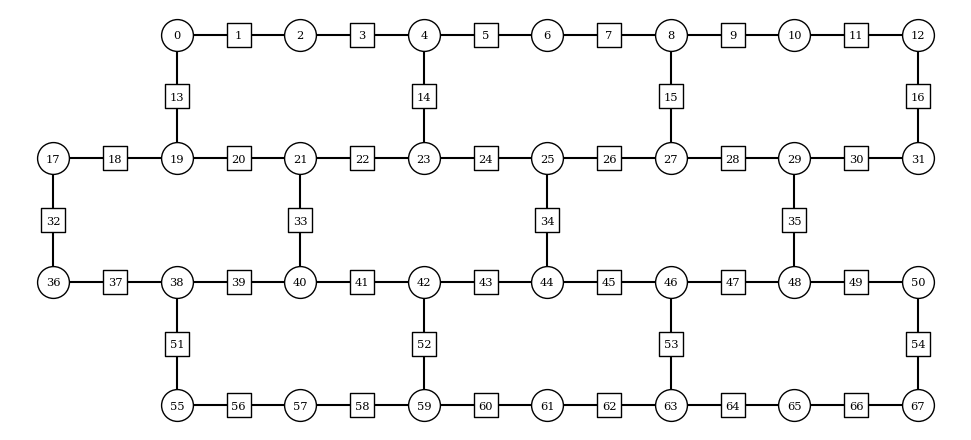

In [153]:
plaquette_width = 3
plaquette_height = 3

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
lattice.plot_lattice(number_qubits=True)

In [154]:
from sympy import symbols

m, g, lamb, t = symbols("m,g,λ,t")

trotter_error(t, lattice, m, g, lamb)

t**3*(152*Abs(g*λ**2) + 800*Abs(m*λ**2))/12 + t**3*(304*Abs(m**2*λ) + 608*Abs(g*m*λ) + 38*Abs(4*g**2*λ + 8*m**2*λ))/24

In [155]:
len(lattice.node_coords)

30

In [156]:
len(lattice.edge_coords)

38

In [157]:
152/38

4.0

In [158]:
608/len(lattice.edge_coords)

16.0

In [159]:
304/38

8.0

76

In [161]:
2*2*25

100

In [162]:
100-76

24

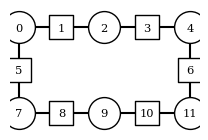

In [176]:
plaquette_width = 1
plaquette_height = 1

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
lattice.plot_lattice(number_qubits=True)

In [177]:
from sympy import symbols

m, g, lamb, t = symbols("m,g,λ,t")

trotter_error(t, lattice, m, g, lamb)

t**3*(24*Abs(g*λ**2) + 96*Abs(m*λ**2))/12 + t**3*(48*Abs(m**2*λ) + 96*Abs(g*m*λ) + 6*Abs(4*g**2*λ + 8*m**2*λ))/24

In [178]:
96/6

16.0

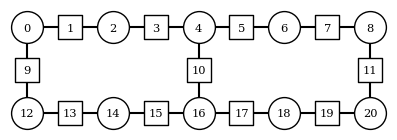

In [179]:
plaquette_width = 2
plaquette_height = 1

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
lattice.plot_lattice(number_qubits=True)

In [180]:
from sympy import symbols

m, g, lamb, t = symbols("m,g,λ,t")

trotter_error(t, lattice, m, g, lamb)

t**3*(44*Abs(g*λ**2) + 200*Abs(m*λ**2))/12 + t**3*(88*Abs(m**2*λ) + 176*Abs(g*m*λ) + 11*Abs(4*g**2*λ + 8*m**2*λ))/24

In [184]:
(200 - (16*8))/2

36.0

In [185]:
16*8 + 36*2

200

## Numerical values

In [205]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
# device = "ibm_marrakesh"
# device = "ibm_aachen"
device = "ibm_kingston"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

/var/folders/t9/xqv32vzn2pb091tj9_rz1_zh0000gn/T/ipykernel_2503/3870600127.py:12: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, ibm_cloud will be the only valid channel. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)


72 possible layouts


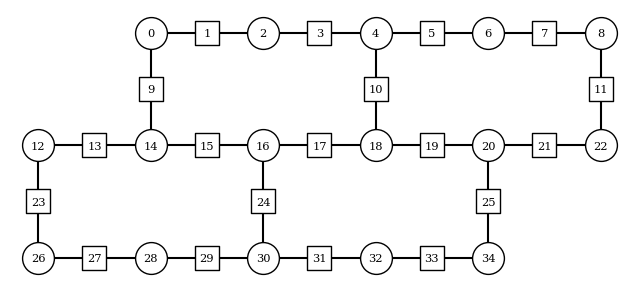

In [207]:
from z2hex.geometry import HeavyHexLattice
 
plaquette_width = 2
plaquette_height = 2

J = 5
h = 2
lamb = 1

dt = 0.15
final_time = 5.1

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
nlayouts = len(lattice.get_all_layouts(backend))
print(f"{nlayouts} possible layouts")
lattice.plot_lattice(number_qubits=True)

In [208]:
from z2hex.circs import trotter_error
import numpy as np

lattice = HeavyHexLattice(plaquette_width, plaquette_height)

settings_error = trotter_error(dt, lattice, J, h, lamb)
sim_max_nlayers = np.ceil(final_time // dt).astype(int)

print(f"With the current simultation settings Δt is at most\nΔt = {dt:.5f}")
print(f"The error per layer commited in the wrost case is\nƐ = {settings_error:.05}")
print(f"The number of layers at the final evolution time is\nN = {sim_max_nlayers} ({6*sim_max_nlayers} 2Qb depth)")

With the current simultation settings Δt is at most
Δt = 0.15000
The error per layer commited in the wrost case is
Ɛ = 2.1105
The number of layers at the final evolution time is
N = 33 (198 2Qb depth)
